# Types of Neural Networks & Their Applications

Neural networks form the backbone of modern deep learning. Different architectures are specialized for different types of data, patterns, and computational tasks. Here is a detailed breakdown of the primary types of neural networks, including their mechanisms and applications:

---

### 1. Artificial Neural Network (ANN) / Feedforward Neural Network
* **Detailed Description:** The simplest form of artificial neural network where connections between nodes do not form a cycle. It consists of an input layer, one or more hidden layers, and an output layer. Every neuron in one layer is typically connected to every neuron in the next layer (fully connected).
* **Key Characteristics:**
  * Information moves in only one direction—forward—from the input nodes, through the hidden nodes, to the output nodes.
  * Uses activation functions (like ReLU, Sigmoid, or Tanh) to introduce non-linearity, allowing the network to learn complex patterns.
  * Uses backpropagation and gradient descent to update weights based on the loss function.
* **Limitations:** Highly inefficient for spatial data (like images) or sequential data (like text) due to a massive number of parameters (parameter explosion) and lack of memory.
* **Key Applications:**
  * **Tabular Data Classification & Regression:** Predicting housing prices, customer churn, or loan approvals based on structured tabular datasets.
  * **Basic Pattern Recognition:** Identifying trends in structured business metrics.

---

### 2. Convolutional Neural Network (CNN)
* **Detailed Description:** A class of deep neural networks specifically designed to process grid-structured data, most commonly visual imagery (2D grids) or audio spectrograms.
* **Key Characteristics:**
  * **Convolutional Layers:** Apply local filters (kernels) to scan the input. This enables *parameter sharing* (the same filter is used across the entire image) and *translation invariance* (detecting a feature regardless of its position).
  * **Pooling Layers:** Max or average pooling downsamples the feature maps, reducing spatial dimensions and computational complexity while retaining dominant features.
  * **Fully Connected Layers:** At the end of the network, the extracted spatial features are flattened and fed into standard dense layers for final classification.
* **Key Applications:**
  * **Computer Vision:** Image classification (e.g., classifying medical scans), object detection (e.g., self-driving car obstacle detection), and facial recognition.
  * **Medical Image Analysis:** Detecting tumors or anomalies in X-rays, MRIs, and CT scans.
  * **Style Transfer & Generative Art:** Creating new images based on artistic styles.

---

### 3. Recurrent Neural Network (RNN)
* **Detailed Description:** A type of neural network designed to handle sequential or time-series data. Unlike feedforward networks, RNNs contain loops that allow information to persist across sequential steps.
* **Key Characteristics:**
  * **Internal Memory:** Utilizes a hidden state ($h_t$) that gets updated at each step, acting as a memory of past inputs in the sequence.
  * **Sequential Processing:** Processes inputs one by one, making it ideal for variable-length input sequences.
* **Limitations:** Suffers from **vanishing and exploding gradient problems**, making it extremely difficult to retain long-term dependencies over long sequences.
* **Key Applications:**
  * **Time-Series Forecasting:** Predicting stock market prices, weather conditions, or electricity demand.
  * **Sentiment Analysis:** Analyzing movie reviews or social media posts to classify sentiment as positive, negative, or neutral.
  * **Speech-to-Text:** Converting spoken language into written text.

---

### 4. Generative Adversarial Network (GAN)
* **Detailed Description:** An unsupervised machine learning framework consisting of two neural networks contesting with each other in a zero-sum game framework.
* **Key Characteristics:**
  * **Generator:** Learns to generate plausible, synthetic data from a random distribution of latent noise. Its goal is to trick the Discriminator.
  * **Discriminator:** Evaluates the input data (both real samples from the dataset and fake generated samples) and tries to classify whether they are real or fake.
  * **Adversarial Training:** The two models are trained simultaneously, continuously pushing each other to improve until the generated data is virtually indistinguishable from real data.
* **Key Applications:**
  * **Image Generation & Super-Resolution:** Generating ultra-realistic human faces (e.g., Deepfakes) and upscaling low-resolution images into high-definition.
  * **Data Augmentation:** Creating synthetic training samples for domains where collecting real-world data is difficult or expensive (such as medical imaging).
  * **Text-to-Image Synthesis:** Creating visuals from natural language descriptions.

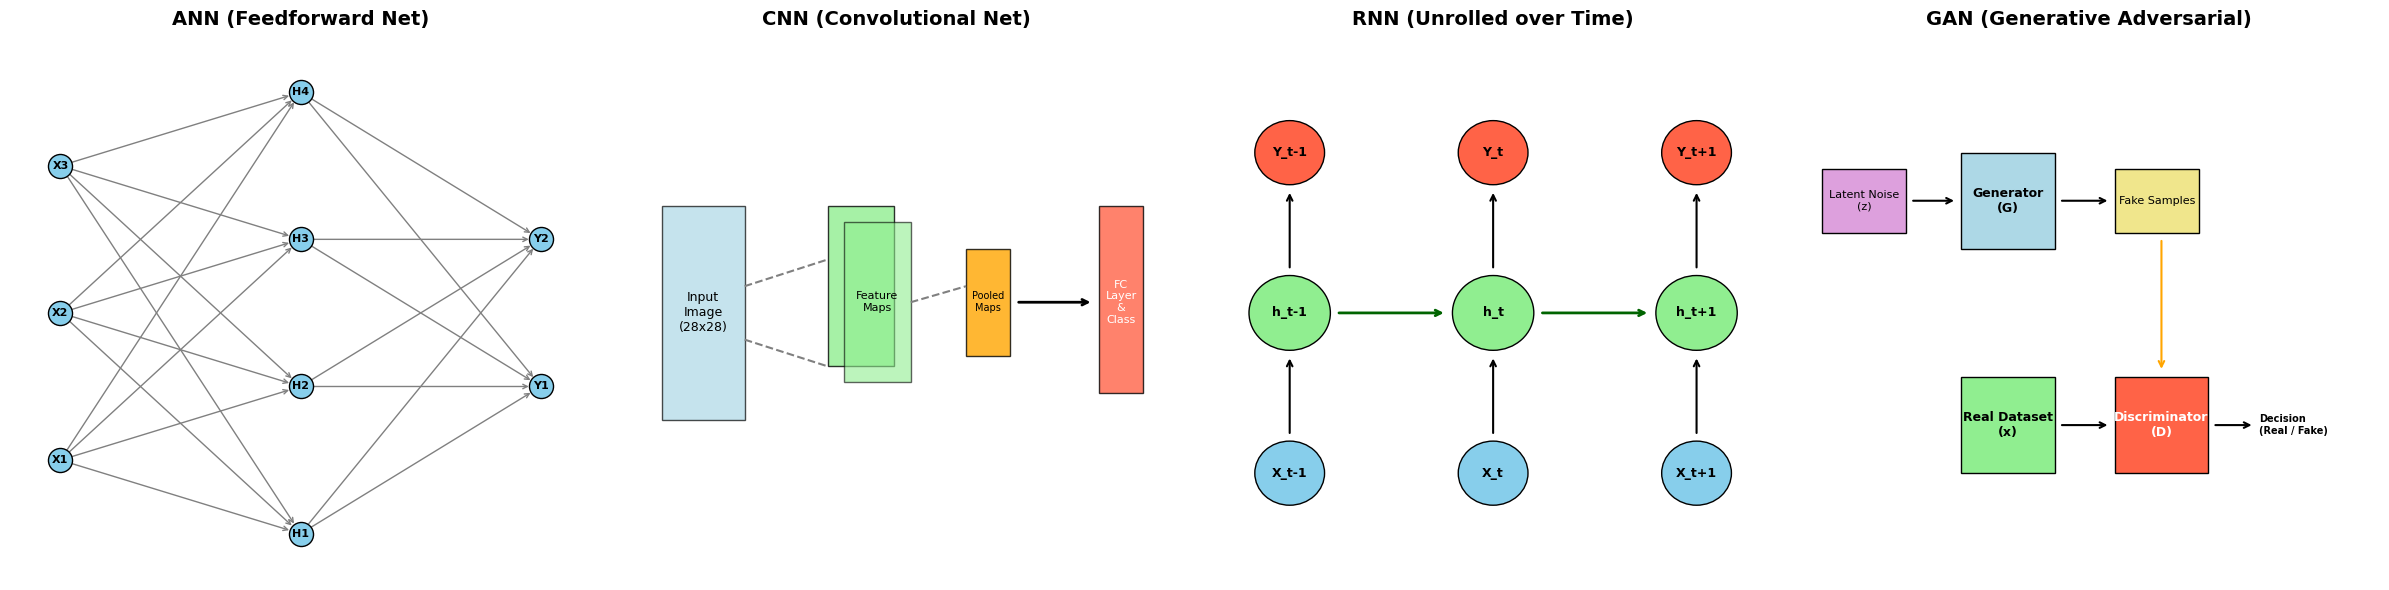

In [3]:
import matplotlib.pyplot as plt
import matplotlib.patches as patches
import networkx as nx

def draw_architectures():
    fig, axes = plt.subplots(1, 4, figsize=(24, 6))

    # ==================== 1. ANN VISUALIZATION ====================
    ax = axes[0]
    ax.set_title("ANN (Feedforward Net)", fontsize=14, fontweight='bold', pad=15)
    G1 = nx.DiGraph()

    layers = {'Input': [1, 2, 3], 'Hidden': [4, 5, 6, 7], 'Output': [8, 9]}
    pos1 = {}
    col_spacing = 2

    # Set node positions
    for col_idx, (layer_name, nodes) in enumerate(layers.items()):
        row_spacing = 1.5
        total_height = (len(nodes) - 1) * row_spacing
        for node_idx, node in enumerate(nodes):
            x = col_idx * col_spacing
            y = (node_idx * row_spacing) - (total_height / 2)
            pos1[node] = (x, y)
            G1.add_node(node, layer=layer_name)

    # Connect fully connected layers
    for u in layers['Input']:
        for v in layers['Hidden']:
            G1.add_edge(u, v)
    for u in layers['Hidden']:
        for v in layers['Output']:
            G1.add_edge(u, v)

    nx.draw_networkx_nodes(G1, pos1, ax=ax, node_size=300, node_color='skyblue', edgecolors='black')
    nx.draw_networkx_edges(G1, pos1, ax=ax, arrowstyle='->', arrowsize=8, edge_color='gray', width=1.0)

    labels = {1: 'X1', 2: 'X2', 3: 'X3', 4: 'H1', 5: 'H2', 6: 'H3', 7: 'H4', 8: 'Y1', 9: 'Y2'}
    nx.draw_networkx_labels(G1, pos1, labels, font_size=8, font_weight='bold', ax=ax)
    ax.axis('off')

    # ==================== 2. CNN VISUALIZATION ====================
    ax = axes[1]
    ax.set_title("CNN (Convolutional Net)", fontsize=14, fontweight='bold', pad=15)

    # Input Image
    ax.add_patch(patches.Rectangle((0.1, 0.3), 0.15, 0.4, edgecolor='black', facecolor='lightblue', alpha=0.7))
    ax.text(0.175, 0.5, "Input\nImage\n(28x28)", ha='center', va='center', fontsize=9)

    # Convolution Filter projection lines
    ax.plot([0.25, 0.4], [0.55, 0.6], color='gray', linestyle='--')
    ax.plot([0.25, 0.4], [0.45, 0.4], color='gray', linestyle='--')

    # Feature Maps
    ax.add_patch(patches.Rectangle((0.4, 0.4), 0.12, 0.3, edgecolor='black', facecolor='lightgreen', alpha=0.8))
    ax.add_patch(patches.Rectangle((0.43, 0.37), 0.12, 0.3, edgecolor='black', facecolor='lightgreen', alpha=0.6))
    ax.text(0.49, 0.52, "Feature\nMaps", ha='center', va='center', fontsize=8)

    # Pooling projection lines
    ax.plot([0.55, 0.65], [0.52, 0.55], color='gray', linestyle='--')

    # Pooled Maps
    ax.add_patch(patches.Rectangle((0.65, 0.42), 0.08, 0.2, edgecolor='black', facecolor='orange', alpha=0.8))
    ax.text(0.69, 0.52, "Pooled\nMaps", ha='center', va='center', fontsize=7)

    # Arrow to FC / Output
    ax.annotate('', xy=(0.88, 0.52), xytext=(0.74, 0.52), arrowprops=dict(arrowstyle="->", lw=2))
    ax.add_patch(patches.Rectangle((0.89, 0.35), 0.08, 0.35, edgecolor='black', facecolor='tomato', alpha=0.8))
    ax.text(0.93, 0.52, "FC\nLayer\n&\nClass", ha='center', va='center', fontsize=8, color='white')

    ax.set_xlim(0, 1.05)
    ax.set_ylim(0, 1)
    ax.axis('off')

    # ==================== 3. RNN (UNROLLED) VISUALIZATION ====================
    ax = axes[2]
    ax.set_title("RNN (Unrolled over Time)", fontsize=14, fontweight='bold', pad=15)

    steps = ['t-1', 't', 't+1']
    x_offsets = [0.15, 0.5, 0.85]

    for i, step in enumerate(steps):
        x = x_offsets[i]
        # Input x_t
        ax.add_patch(patches.Circle((x, 0.2), 0.06, edgecolor='black', facecolor='skyblue'))
        ax.text(x, 0.2, f"X_{step}", ha='center', va='center', fontsize=9, fontweight='bold')

        # Hidden state h_t
        ax.add_patch(patches.Circle((x, 0.5), 0.07, edgecolor='black', facecolor='lightgreen'))
        ax.text(x, 0.5, f"h_{step}", ha='center', va='center', fontsize=9, fontweight='bold')

        # Output y_t
        ax.add_patch(patches.Circle((x, 0.8), 0.06, edgecolor='black', facecolor='tomato'))
        ax.text(x, 0.8, f"Y_{step}", ha='center', va='center', fontsize=9, fontweight='bold')

        # Vertical arrows (Input -> Hidden -> Output)
        ax.annotate('', xy=(x, 0.42), xytext=(x, 0.27), arrowprops=dict(arrowstyle="->", lw=1.5))
        ax.annotate('', xy=(x, 0.73), xytext=(x, 0.58), arrowprops=dict(arrowstyle="->", lw=1.5))

    # Horizontal arrows between Hidden states
    ax.annotate('', xy=(0.42, 0.5), xytext=(0.23, 0.5), arrowprops=dict(arrowstyle="->", lw=2, color='darkgreen'))
    ax.annotate('', xy=(0.77, 0.5), xytext=(0.58, 0.5), arrowprops=dict(arrowstyle="->", lw=2, color='darkgreen'))

    ax.set_xlim(0, 1)
    ax.set_ylim(0, 1)
    ax.axis('off')

    # ==================== 4. GAN VISUALIZATION ====================
    ax = axes[3]
    ax.set_title("GAN (Generative Adversarial)", fontsize=14, fontweight='bold', pad=15)

    # Latent Noise
    ax.add_patch(patches.Rectangle((0.05, 0.65), 0.18, 0.12, edgecolor='black', facecolor='plum'))
    ax.text(0.14, 0.71, "Latent Noise\n(z)", ha='center', va='center', fontsize=8)

    # Generator
    ax.add_patch(patches.Rectangle((0.35, 0.62), 0.2, 0.18, edgecolor='black', facecolor='lightblue'))
    ax.text(0.45, 0.71, "Generator\n(G)", ha='center', va='center', fontsize=9, fontweight='bold')

    # Generated Data
    ax.add_patch(patches.Rectangle((0.68, 0.65), 0.18, 0.12, edgecolor='black', facecolor='khaki'))
    ax.text(0.77, 0.71, "Fake Samples", ha='center', va='center', fontsize=8)

    # Real Data Source
    ax.add_patch(patches.Rectangle((0.35, 0.2), 0.2, 0.18, edgecolor='black', facecolor='lightgreen'))
    ax.text(0.45, 0.29, "Real Dataset\n(x)", ha='center', va='center', fontsize=9, fontweight='bold')

    # Discriminator
    ax.add_patch(patches.Rectangle((0.68, 0.2), 0.2, 0.18, edgecolor='black', facecolor='tomato'))
    ax.text(0.78, 0.29, "Discriminator\n(D)", ha='center', va='center', fontsize=9, fontweight='bold', color='white')

    # Arrows connecting components
    ax.annotate('', xy=(0.34, 0.71), xytext=(0.24, 0.71), arrowprops=dict(arrowstyle="->", lw=1.5))
    ax.annotate('', xy=(0.67, 0.71), xytext=(0.56, 0.71), arrowprops=dict(arrowstyle="->", lw=1.5))

    # Real Data to Discriminator
    ax.annotate('', xy=(0.67, 0.29), xytext=(0.56, 0.29), arrowprops=dict(arrowstyle="->", lw=1.5))
    # Fake Data to Discriminator
    ax.annotate('', xy=(0.78, 0.39), xytext=(0.78, 0.64), arrowprops=dict(arrowstyle="->", lw=1.5, color='orange'))

    # Discriminator Output (Real / Fake)
    ax.annotate('', xy=(0.98, 0.29), xytext=(0.89, 0.29), arrowprops=dict(arrowstyle="->", lw=1.5))
    ax.text(0.99, 0.29, "Decision\n(Real / Fake)", ha='left', va='center', fontsize=7, color='black', fontweight='bold')

    ax.set_xlim(0, 1.25)
    ax.set_ylim(0, 1)
    ax.axis('off')

    plt.tight_layout()
    plt.show()

draw_architectures()